Project 10: Road Accident Severity Prediction.

IMPORTING IMPORTANT LIBRARIES

In [ ]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

1. Load Dataset

In [ ]:
df = pd.read_csv("/content/rta_dataset.csv")
df

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Vehicle_movement,Casualty_class,Sex_of_casualty,Cause_of_accident
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,Going straight,na,na,Moving Backward
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,Going straight,na,na,Overtaking
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,Going straight,Driver or rider,Male,Changing lane to the left
3,01:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,Going straight,Pedestrian,Female,Changing lane to the right
4,01:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,Going straight,na,na,Overtaking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12311,16:15:00,Wednesday,31-50,Male,NaN,Employee,2-5yr,Lorry (11?40Q),Owner,NaN,...,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,Going straight,na,na,No distancing
12312,18:00:00,Sunday,Unknown,Male,Elementary school,Employee,5-10yr,Automobile,Owner,NaN,...,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,Other,na,na,No distancing
12313,13:55:00,Sunday,Over 51,Male,Junior high school,Employee,5-10yr,Bajaj,Owner,2-5yrs,...,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,1,Other,Driver or rider,Male,Changing lane to the right
12314,13:55:00,Sunday,18-30,Female,Junior high school,Employee,Above 10yr,Lorry (41?100Q),Owner,2-5yrs,...,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,Other,na,na,Driving under the influence of drugs


In [ ]:
for i, col in enumerate(df.columns):
    print(f"{i}: {repr(col)}")

0: 'Time'
1: 'Day_of_week'
2: 'Age_band_of_driver'
3: 'Sex_of_driver'
4: 'Educational_level'
5: 'Vehicle_driver_relation'
6: 'Driving_experience'
7: 'Type_of_vehicle'
8: 'Owner_of_vehicle'
9: 'Service_year_of_vehicle'
10: 'Defect_of_vehicle'
11: 'Area_accident_occured'
12: 'Lanes_or_Medians'
13: 'Road_allignment'
14: 'Types_of_Junction'
15: 'Road_surface_type'
16: 'Road_surface_conditions'
17: 'Light_conditions'
18: 'Weather_conditions'
19: 'Type_of_collision'
20: 'Number_of_vehicles_involved'
21: 'Vehicle_movement'
22: 'Casualty_class'
23: 'Sex_of_casualty'
24: 'Cause_of_accident'


## 2. Exploratory Data Analysis (EDA) & Missing Values

In [ ]:
# Print all column names cleanly
"All columns:", list(df.columns)

# Try finding a severity-related column automatically
severity_cols = [c for c in df.columns if "sever" in c.lower()]
print("Possible severity columns:", severity_cols)

if severity_cols:
    target_col = severity_cols[0]
    print("\nUsing target_col:", target_col)
    print("\nTarget Class Counts:\n", df[target_col].value_counts(dropna=False))
    print("\nTarget Class %:\n", (df[target_col].value_counts(normalize=True, dropna=False) * 100).round(2))

missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_%": missing_pct})
print("\nTop Missing Columns:\n", missing_table[missing_table["missing_count"] > 0].sort_values("missing_count", ascending=False).head(15))

Possible severity columns: []

Top Missing Columns:
                          missing_count  missing_%
Defect_of_vehicle                 4427      35.95
Service_year_of_vehicle           3928      31.89
Type_of_vehicle                    950       7.71
Types_of_Junction                  887       7.20
Driving_experience                 829       6.73
Educational_level                  741       6.02
Vehicle_driver_relation            579       4.70
Owner_of_vehicle                   482       3.91
Lanes_or_Medians                   385       3.13
Vehicle_movement                   308       2.50
Area_accident_occured              239       1.94
Road_surface_type                  172       1.40
Type_of_collision                  155       1.26
Road_allignment                    142       1.15


# 3. Inspect All 25 Columns & Sample Values

In [ ]:
for idx, col in enumerate(df.columns):
    uniq = df[col].dropna().unique()[:5]
    print(f"{idx:2d}. {col} (missing={df[col].isnull().sum()}) -> sample: {list(uniq)}")

 0. Time (missing=0) -> sample: ['17:02:00', '01:06:00', '14:15:00', '17:30:00', '17:20:00']
 1. Day_of_week (missing=0) -> sample: ['Monday', 'Sunday', 'Friday', 'Wednesday', 'Saturday']
 2. Age_band_of_driver (missing=0) -> sample: ['18-30', '31-50', 'Under 18', 'Over 51', 'Unknown']
 3. Sex_of_driver (missing=0) -> sample: ['Male', 'Female', 'Unknown']
 4. Educational_level (missing=741) -> sample: ['Above high school', 'Junior high school', 'Elementary school', 'High school', 'Unknown']
 5. Vehicle_driver_relation (missing=579) -> sample: ['Employee', 'Unknown', 'Owner', 'Other']
 6. Driving_experience (missing=829) -> sample: ['1-2yr', 'Above 10yr', '5-10yr', '2-5yr', 'No Licence']
 7. Type_of_vehicle (missing=950) -> sample: ['Automobile', 'Public (> 45 seats)', 'Lorry (41?100Q)', 'Public (13?45 seats)', 'Lorry (11?40Q)']
 8. Owner_of_vehicle (missing=482) -> sample: ['Owner', 'Governmental', 'Organization', 'Other']
 9. Service_year_of_vehicle (missing=3928) -> sample: ['Above 1

#4. Target Selection (Casualty_class)

In [ ]:
target_col = "Casualty_class"
df_clean = df.dropna(subset=[target_col]).copy()

#5. Feature Engineering (Accident Hour) & Target Distribution

In [ ]:
if "Time" in df_clean.columns:
    df_clean["Accident_hour"] = pd.to_datetime(
        df_clean["Time"], format="%H:%M:%S", errors="coerce"
    ).dt.hour
    df_clean = df_clean.drop(columns=["Time"])

y = df_clean[target_col].astype(str)
X = df_clean.drop(columns=[target_col])

print("Target classes:\n", y.value_counts())
print("\nX shape:", X.shape)

Target classes:
 Casualty_class
Driver or rider    4944
na                 4443
Pedestrian         1649
Passenger          1280
Name: count, dtype: int64

X shape: (12316, 24)


# 6. Preprocessing Pipeline & Stratified Train-Test Split

In [ ]:
num_cols = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Numeric cols:", len(num_cols), "| Categorical cols:", len(cat_cols))

Train shape: (9852, 24) | Test shape: (2464, 24)
Numeric cols: 2 | Categorical cols: 22


# 7. Baseline Model — Logistic Regression (5-Fold CV)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

cv_f1 = cross_val_score(baseline_pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
baseline_pipe.fit(X_train, y_train)
base_preds = baseline_pipe.predict(X_test)

metrics_df = pd.DataFrame([{
    "CV Macro F1 Mean": round(float(cv_f1.mean()), 4),
    "CV Macro F1 Std": round(float(cv_f1.std()), 4),
    "Test Accuracy": round(float(accuracy_score(y_test, base_preds)), 4),
    "Test Macro F1": round(float(f1_score(y_test, base_preds, average="macro")), 4),
}])

report_df = pd.DataFrame(classification_report(y_test, base_preds, output_dict=True)).transpose().round(4)

metrics_df

,CV Macro F1 Mean,CV Macro F1 Std,Test Accuracy,Test Macro F1
0,0.5742,0.0096,0.711,0.5717


In [ ]:
report_df

,precision,recall,f1-score,support
Driver or rider,0.7575,0.6916,0.7230,989.000
Passenger,0.2832,0.4414,0.3450,256.000
Pedestrian,0.2418,0.2000,0.2189,330.000
na,1.0000,1.0000,1.0000,889.000
accuracy,0.7110,0.7110,0.7110,0.711
macro avg,0.5706,0.5833,0.5717,2464.000
weighted avg,0.7266,0.7110,0.7162,2464.000


# 8. Ensemble Models Comparison (Random Forest & Gradient Boosting)

In [ ]:
ensemble_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=14, class_weight="balanced", n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

rows = [{
    "Model": "Logistic Regression (Baseline)",
    "CV Macro F1": round(float(metrics_df.loc[0, "CV Macro F1 Mean"]), 4),
    "Test Accuracy": round(float(metrics_df.loc[0, "Test Accuracy"]), 4),
    "Test Macro F1": round(float(metrics_df.loc[0, "Test Macro F1"]), 4),
}]

fitted_models = {"Logistic Regression (Baseline)": (baseline_pipe, base_preds)}

for name, clf in ensemble_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    rows.append({
        "Model": name,
        "CV Macro F1": round(float(cv_scores.mean()), 4),
        "Test Accuracy": round(float(accuracy_score(y_test, preds)), 4),
        "Test Macro F1": round(float(f1_score(y_test, preds, average="macro")), 4),
    })
    fitted_models[name] = (pipe, preds)

comparison_df = pd.DataFrame(rows).sort_values("Test Macro F1", ascending=False).reset_index(drop=True)
comparison_df

,Model,CV Macro F1,Test Accuracy,Test Macro F1
0,Random Forest,0.5787,0.7541,0.5763
1,Logistic Regression (Baseline),0.5742,0.7110,0.5717
2,Gradient Boosting,0.5106,0.7537,0.4860


# 9. Confusion Matrix — Best Model (Random Forest)

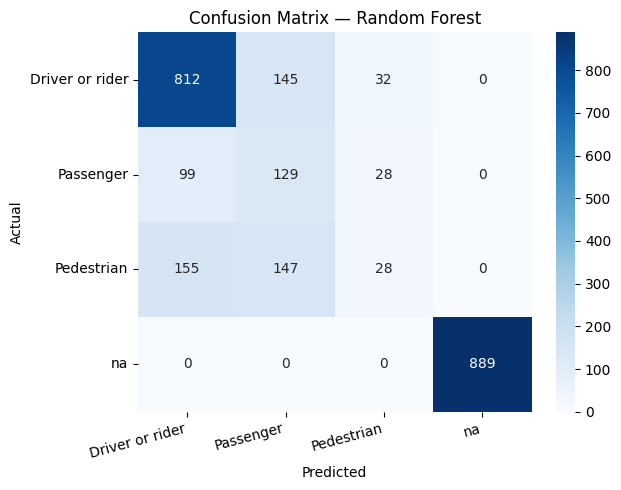

In [ ]:
best_name = comparison_df.loc[0, "Model"]
best_pipe, best_preds = fitted_models[best_name]
labels = sorted(y.unique())

cm = confusion_matrix(y_test, best_preds, labels=labels)

plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=15, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 10. Top 12 Feature Importances — Random Forest

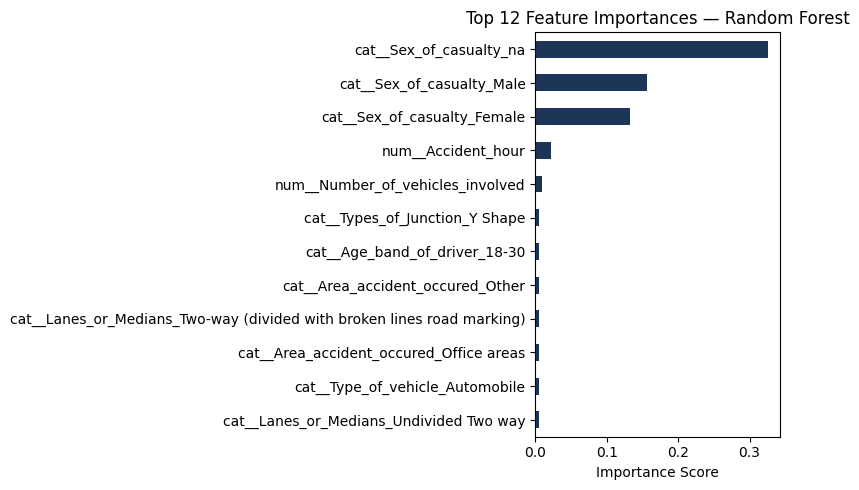

In [ ]:
model_step = best_pipe.named_steps["model"]
prep_step = best_pipe.named_steps["prep"]

feat_names = prep_step.get_feature_names_out()
top_imp = (
    pd.Series(model_step.feature_importances_, index=feat_names)
    .sort_values(ascending=False)
    .head(12)
)

plt.figure(figsize=(8, 5))
top_imp.sort_values().plot(kind="barh", color="#1D3557")
plt.title(f"Top 12 Feature Importances — {best_name}")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# 11. High-Risk Condition Analysis (Pedestrian Share by Lighting)

In [ ]:
risk_by_light = (
    df_clean.assign(is_pedestrian=(df_clean[target_col] == "Pedestrian").astype(int))
    .groupby("Light_conditions", dropna=False)["is_pedestrian"]
    .agg(total_cases="count", pedestrian_count="sum", pedestrian_share="mean")
    .sort_values("pedestrian_share", ascending=False)
    .round(4)
)

risk_by_light

,total_cases,pedestrian_count,pedestrian_share
Light_conditions,,,
Darkness - lights unlit,40,6,0.1500
Darkness - lights lit,3286,472,0.1436
Daylight,8798,1146,0.1303
Darkness - no lighting,192,25,0.1302
